In [ ]:
# INSTALL & IMPORT LIBRARY

!pip install rasterio --quiet

import os
import numpy as np
import rasterio
from rasterio.windows import Window
from scipy import stats
from PIL import Image
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

import torch

print("CUDA tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CUDA tersedia: True
GPU: Tesla T4


In [ ]:
# KONFIGURASI GLOBAL


# Path folder tempat file GeoTIFF hasil export GEE disimpan

FOLDER_GEE = '/content/drive/MyDrive/SolarPanel_Dataset_2024'

# Path folder output
FOLDER_OUTPUT_DRIVE = '/content/drive/MyDrive/SolarPanel_Preprocessing'

# Path folder sementara di disk lokal collab
FOLDER_TILE_MENTAH = '/content/AllTiles_local'

# Daftar kota
DAFTAR_KOTA = [
    'BandaAceh', 'Jakarta', 'Bandung', 'Yogyakarta', 'Surabaya',
    'Kediri', 'Denpasar', 'Pontianak', 'Makassar', 'Jayapura'
]

# Ukuran tile untuk CNN
UKURAN_TILE = 224

# Ambang batas proporsi piksel kosong (nodata) yang masih ditoleransi
AMBANG_PIKSEL_KOSONG = 0.05

# Cetak progress setiap berapa tile (supaya tahu progres kota besar)
INTERVAL_PROGRESS = 100

# Legenda kelas Dynamic World (untuk dokumentasi & referensi)
LEGENDA_DW = {
    0: 'Water', 1: 'Trees', 2: 'Grass', 3: 'Flooded_veg',
    4: 'Crops', 5: 'Shrub_Scrub', 6: 'Built', 7: 'Bare', 8: 'Snow_Ice'
}

# Buat folder output (LOKAL, bukan Drive)
os.makedirs(FOLDER_TILE_MENTAH, exist_ok=True)
os.makedirs(FOLDER_OUTPUT_DRIVE, exist_ok=True)

In [ ]:
# FUNGSI BANTU - VISUALISASI NATURAL + PENINGKATAN KONTRAS
def stretch_kontras(tile_rgb, vmin=0.01, vmax=0.28, gamma=1.3):
    """
    Menghasilkan citra natural dengan tambahan kontras.
    vmin=0.01: Membuat area bayangan/gelap menjadi lebih pekat (menambah kontras).
    vmax=0.28: Membuat area terang (bangunan/tanah) lebih menonjol.
    gamma=1.3: Mencerahkan mid-tone secara proporsional.
    """
    # 1. Potong nilai ekstrem bawah dan atas
    img = np.clip(tile_rgb, vmin, vmax)

    # 2. Normalisasi nilai ke rentang 0.0 - 1.0
    img = (img - vmin) / (vmax - vmin)

    # 3. Terapkan Koreksi Gamma untuk menjaga detail di area yang agak gelap
    img_gamma = np.power(img, 1.0 / gamma)

    # 4. Konversi ke format gambar standar 8-bit (0-255)
    hasil = (img_gamma * 255).astype(np.uint8)

    return hasil

In [ ]:
# FUNGSI BANTU - CEK APAKAH TILE VALID (BUKAN AREA KOSONG)

def tile_valid(tile_rgb, ambang_kosong=AMBANG_PIKSEL_KOSONG):

    """
    Mengecek apakah proporsi piksel kosong (nilai 0 di semua band)
    dalam tile masih di bawah ambang batas yang diizinkan.
    Return: (bool valid, float proporsi_kosong)
    """
    piksel_kosong = np.all(tile_rgb == 0, axis=-1)
    proporsi_kosong = float(np.sum(piksel_kosong) / piksel_kosong.size)
    return proporsi_kosong < ambang_kosong, proporsi_kosong

In [ ]:
# FUNGSI AUGMENTASI (DIDEFINISIKAN DI SINI, DIPAKAI DI TAHAP LABELING)

# Augmentasi TIDAK diterapkan secara otomatis pada tahap preprocessing
# ini. Fungsi-fungsi di bawah ini hanya DIDEFINISIKAN di sini agar siap
# dipakai, tapi baru akan DIPANGGIL/DIEKSEKUSI pada script tahap
# PELABELAN berikutnya - khususnya untuk menambah jumlah tile pada
# kelas yang jumlahnya kurang saat proses balancing dataset


def augmentasi_flip_horizontal(citra_array):
    """[AUGMENTASI] Membalik citra secara horizontal (efek cermin kiri-kanan)."""
    return np.fliplr(citra_array)

def augmentasi_flip_vertikal(citra_array):
    """[AUGMENTASI] Membalik citra secara vertikal (efek cermin atas-bawah)."""
    return np.flipud(citra_array)

def augmentasi_rotasi(citra_array, sudut_derajat):
    """[AUGMENTASI] Memutar citra sebesar 90, 180, atau 270 derajat."""
    k = int(sudut_derajat / 90)
    return np.rot90(citra_array, k=k)

def augmentasi_kecerahan(citra_array, faktor=1.2):
    """[AUGMENTASI] Mengubah tingkat kecerahan citra (faktor>1 lebih terang,
    faktor<1 lebih gelap). Nilai piksel di-clip agar tetap dalam rentang 0-255."""
    hasil = citra_array.astype(np.float32) * faktor
    return np.clip(hasil, 0, 255).astype(np.uint8)

# Fungsi-fungsi di atas TIDAK dipanggil di script ini.
# Akan dipanggil di script tahap Pelabelan pada bagian balancing dataset.

In [ ]:
# FUNGSI UTAMA - PREPROCESSING PER KOTA (TILING + EKSTRAKSI PARAMETER)

def tile_valid_v2(window, src_rgb, src_dw, src_slope, src_ghi,
                   ambang_kosong=AMBANG_PIKSEL_KOSONG):
    """
    Cek validitas tile menggunakan mask nodata ASLI dari setiap raster,
    diperiksa di SEMUA layer (RGB, DW, Slope, GHI) - BUKAN cek nilai==0.

    Nilai default ambang_kosong DIAMBIL dari variabel global
    AMBANG_PIKSEL_KOSONG yang didefinisikan di Cell 2 - supaya hanya
    ADA SATU tempat untuk mengatur nilai ini, tidak di-hardcode
    terpisah di sini.

    Return: (bool valid, dict detail_proporsi_kosong_per_layer)
    """
    detail = {}

    mask_rgb   = src_rgb.read_masks(1, window=window)
    mask_dw    = src_dw.read_masks(1, window=window)
    mask_slope = src_slope.read_masks(1, window=window)
    mask_ghi   = src_ghi.read_masks(1, window=window)

    for nama, mask in [('rgb', mask_rgb), ('dw', mask_dw),
                        ('slope', mask_slope), ('ghi', mask_ghi)]:
        proporsi_kosong = float(1.0 - (mask > 0).sum() / mask.size)
        detail[nama] = round(proporsi_kosong, 4)

    valid = all(p < ambang_kosong for p in detail.values())
    return valid, detail


def preprocessing_kota(nama_kota):
    """
    Membaca 4 file GeoTIFF (RGB, Dynamic World, Slope, GHI) untuk 1 kota,
    memotongnya menjadi tile 224x224, menyimpan tile RGB sebagai PNG,
    serta mengekstrak parameter MENTAH (belum dilabel) per tile:
    kelas tutupan lahan dominan, rata-rata slope, rata-rata GHI.

    TIDAK melakukan pelabelan Potential/Not_Potential - itu dilakukan
    di script terpisah pada tahap berikutnya.

    Return: list of dict berisi metadata mentah setiap tile valid
    """

    print(f'\n{"="*60}')
    print(f'PREPROCESSING kota: {nama_kota}')
    print(f'{"="*60}')

    path_rgb   = os.path.join(FOLDER_GEE, f'S2_RGB_{nama_kota}.tif')
    path_dw    = os.path.join(FOLDER_GEE, f'DW_LC_{nama_kota}.tif')
    path_slope = os.path.join(FOLDER_GEE, f'SLOPE_{nama_kota}.tif')
    path_ghi   = os.path.join(FOLDER_GEE, f'GHI_{nama_kota}.tif')

    # Cek keberadaan file
    for p in [path_rgb, path_dw, path_slope, path_ghi]:
        if not os.path.exists(p):
            print(f'  ⚠️  File tidak ditemukan: {p}')
            return []

    # --- Buka semua raster (tidak langsung load penuh ke memori,
    #     dibaca per-window/per-tile agar hemat memori untuk
    #     polygon custom yang mungkin jauh lebih besar dari sebelumnya) ---
    src_rgb   = rasterio.open(path_rgb)
    src_dw    = rasterio.open(path_dw)
    src_slope = rasterio.open(path_slope)
    src_ghi   = rasterio.open(path_ghi)

    # --- Samakan dimensi (ambil ukuran minimum bersama, jaga-jaga
    #     ada selisih piksel antar file akibat proses export GEE) ---
    tinggi = min(src_rgb.height, src_dw.height, src_slope.height, src_ghi.height)
    lebar  = min(src_rgb.width,  src_dw.width,  src_slope.width,  src_ghi.width)

    print(f'  Dimensi citra (piksel)      : {lebar} x {tinggi}')
    print(f'  Luas area (perkiraan km2)   : {(lebar*10/1000) * (tinggi*10/1000):.1f}')

    n_tile_baris = tinggi // UKURAN_TILE
    n_tile_kolom = lebar  // UKURAN_TILE
    print(f'  Estimasi maksimum tile      : {n_tile_baris * n_tile_kolom}')

    daftar_metadata = []
    counter_valid   = 0
    counter_dibuang = 0

    # --- Loop setiap tile (non-overlapping) ---
    for baris in range(n_tile_baris):
        for kolom in range(n_tile_kolom):

            row_off = baris * UKURAN_TILE
            col_off = kolom * UKURAN_TILE
            window  = Window(col_off, row_off, UKURAN_TILE, UKURAN_TILE)

            # Cek validitas PALING AWAL, SEBELUM baca array data sungguhan
            # Ambang batas diambil OTOMATIS dari AMBANG_PIKSEL_KOSONG
            # di Cell 2 (tidak di-hardcode di sini

            valid, detail_kosong = tile_valid_v2(
                window, src_rgb, src_dw, src_slope, src_ghi
            )
            if not valid:
                counter_dibuang += 1
                continue

            # --- Baca tile RGB (band 1,2,3 = Red, Green, Blue) ---
            tile_rgb = src_rgb.read([1, 2, 3], window=window)
            tile_rgb = np.transpose(tile_rgb, (1, 2, 0))  # (H,W,3)
            tile_rgb = np.nan_to_num(tile_rgb, nan=0.0)

            # --- Baca tile Dynamic World (tutupan lahan) ---
            tile_dw = src_dw.read(1, window=window)
            tile_dw_valid = tile_dw[tile_dw >= 0]
            if len(tile_dw_valid) == 0:
                counter_dibuang += 1
                continue
            kelas_dominan = int(stats.mode(tile_dw_valid, axis=None, keepdims=False).mode)

            # --- Baca tile Slope ---
            tile_slope = src_slope.read(1, window=window)
            if np.all(np.isnan(tile_slope)):
                counter_dibuang += 1
                continue
            slope_ratarata = float(np.nanmean(tile_slope))

            # --- Baca tile GHI ---
            tile_ghi = src_ghi.read(1, window=window)
            if np.all(np.isnan(tile_ghi)):
                counter_dibuang += 1
                continue
            ghi_ratarata = float(np.nanmean(tile_ghi))

            # --- Simpan tile RGB sebagai PNG (contrast stretch, BUKAN augmentasi) ---
            nama_file = f'{nama_kota}_r{baris}_c{kolom}.png'
            path_simpan = os.path.join(FOLDER_TILE_MENTAH, nama_file)

            citra_stretch = stretch_kontras(tile_rgb)

            # try-except di sini: kalau SATU tile gagal ditulis (misal
            # gangguan I/O sesaat), tile itu di-skip dan proses tetap
            # LANJUT ke tile berikutnya - tidak menghentikan seluruh
            # proses preprocessing kota tersebut.
            try:
                Image.fromarray(citra_stretch).save(path_simpan)
            except Exception as e:
                print(f'  ⚠️  Gagal simpan {nama_file}: {e}')
                counter_dibuang += 1
                continue

            # --- Catat metadata MENTAH (belum ada keputusan label) ---
            daftar_metadata.append({
                'filename'          : nama_file,
                'kota'              : nama_kota,
                'baris'             : baris,
                'kolom'             : kolom,
                'kelas_lc_kode'     : kelas_dominan,
                'kelas_lc_nama'     : LEGENDA_DW.get(kelas_dominan, 'Unknown'),
                'slope_rata2'       : round(slope_ratarata, 3),
                'ghi_rata2'         : round(ghi_ratarata, 3),
                'kosong_rgb'        : detail_kosong['rgb'],
                'kosong_dw'         : detail_kosong['dw'],
                'kosong_slope'      : detail_kosong['slope'],
                'kosong_ghi'        : detail_kosong['ghi'],
            })
            counter_valid += 1

            # --- Progress tracker (khusus kota besar seperti Jakarta) ---
            if counter_valid % INTERVAL_PROGRESS == 0:
                print(f'    ... {counter_valid} tile tersimpan sejauh ini')

    src_rgb.close()
    src_dw.close()
    src_slope.close()
    src_ghi.close()

    print(f'  ✓ Tile valid disimpan  : {counter_valid}')
    print(f'  ✗ Tile dibuang (kosong): {counter_dibuang}')

    return daftar_metadata

In [ ]:
# JALANKAN PREPROCESSING UNTUK SEMUA KOTA

semua_metadata_mentah = []

for kota in DAFTAR_KOTA:
    hasil = preprocessing_kota(kota)
    semua_metadata_mentah.extend(hasil)

df_mentah = pd.DataFrame(semua_metadata_mentah)

print(f'\n{"="*60}')
print('RINGKASAN HASIL PREPROCESSING (BELUM DILABEL)')
print(f'{"="*60}')
print(f'Total tile valid yang berhasil diproses: {len(df_mentah)}')
print(f'\nJumlah tile per kota:')
print(df_mentah['kota'].value_counts())
print(f'\nDistribusi kelas tutupan lahan dominan (mentah):')
print(df_mentah['kelas_lc_nama'].value_counts())
print(f'\nStatistik Slope (derajat):')
print(df_mentah['slope_rata2'].describe())
print(f'\nStatistik GHI (kWh/m2/hari):')
print(df_mentah['ghi_rata2'].describe())


PREPROCESSING kota: BandaAceh
  Dimensi citra (piksel)      : 2951 x 2146
  Luas area (perkiraan km2)   : 633.3
  Estimasi maksimum tile      : 117
    ... 100 tile tersimpan sejauh ini
  ✓ Tile valid disimpan  : 117
  ✗ Tile dibuang (kosong): 0

PREPROCESSING kota: Jakarta
  Dimensi citra (piksel)      : 10458 x 7142
  Luas area (perkiraan km2)   : 7469.1
  Estimasi maksimum tile      : 1426
    ... 100 tile tersimpan sejauh ini
    ... 200 tile tersimpan sejauh ini
    ... 300 tile tersimpan sejauh ini
    ... 400 tile tersimpan sejauh ini
    ... 500 tile tersimpan sejauh ini
    ... 600 tile tersimpan sejauh ini
    ... 700 tile tersimpan sejauh ini
    ... 800 tile tersimpan sejauh ini
    ... 900 tile tersimpan sejauh ini
    ... 1000 tile tersimpan sejauh ini
    ... 1100 tile tersimpan sejauh ini
    ... 1200 tile tersimpan sejauh ini
    ... 1300 tile tersimpan sejauh ini
    ... 1400 tile tersimpan sejauh ini
  ✓ Tile valid disimpan  : 1426
  ✗ Tile dibuang (kosong): 0

PREP

In [ ]:
# PINDAHKAN HASIL DARI DISK LOKAL KE GOOGLE DRIVE

import shutil

print('Membuat file zip dari hasil tile lokal...')
path_zip = shutil.make_archive(
    base_name = '/content/AllTiles_backup',   # tanpa ekstensi .zip
    format    = 'zip',
    root_dir  = FOLDER_TILE_MENTAH
)
print(f'✓ Zip berhasil dibuat: {path_zip}')

# --- Salin file zip ke Drive (1 file besar, jauh lebih stabil) ---
path_zip_drive = os.path.join(FOLDER_OUTPUT_DRIVE, 'AllTiles_backup.zip')
print(f'\nMenyalin zip ke Google Drive...')
shutil.copy(path_zip, path_zip_drive)
print(f'✓ Berhasil disalin ke: {path_zip_drive}')

# --- Simpan juga CSV metadata langsung ke Drive (ukurannya kecil,
#     jadi aman ditulis langsung tanpa perlu di-zip) ---
path_csv_drive = os.path.join(FOLDER_OUTPUT_DRIVE, 'parameter_mentah_per_tile.csv')
df_mentah.to_csv(path_csv_drive, index=False)
print(f'✓ Metadata CSV disimpan ke: {path_csv_drive}')

print(f'\n{"="*60}')
print('SELESAI - Semua hasil sudah aman tersimpan di Google Drive')
print(f'{"="*60}')
print(f'Total tile dalam zip: {len(df_mentah)}')

Membuat file zip dari hasil tile lokal...
✓ Zip berhasil dibuat: /content/AllTiles_backup.zip

Menyalin zip ke Google Drive...
✓ Berhasil disalin ke: /content/drive/MyDrive/SolarPanel_Preprocessing/AllTiles_backup.zip
✓ Metadata CSV disimpan ke: /content/drive/MyDrive/SolarPanel_Preprocessing/parameter_mentah_per_tile.csv

SELESAI - Semua hasil sudah aman tersimpan di Google Drive
Total tile dalam zip: 4705

CATATAN: Kalau butuh tile individual (bukan dalam bentuk zip),
ekstrak file AllTiles_backup.zip langsung di Google Drive
(klik kanan -> Ekstrak), atau lanjutkan ke tahap Pelabelan
menggunakan file zip ini langsung (baca dari dalam zip tanpa
perlu ekstrak, lebih hemat storage Drive).


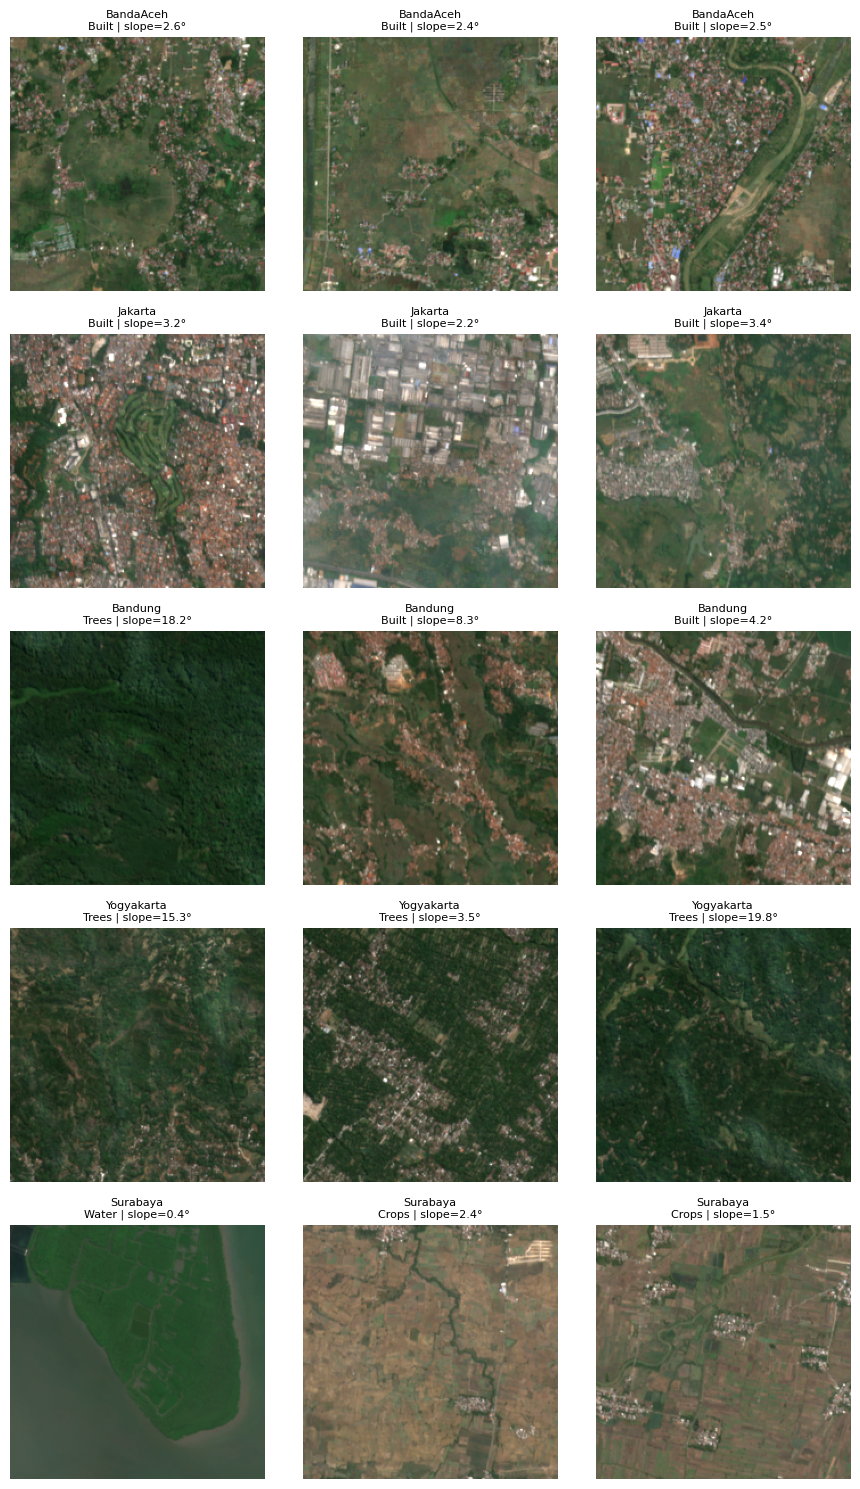

In [ ]:
# VERIFIKASI VISUAL - TAMPILKAN CONTOH TILE PER KOTA

import matplotlib.pyplot as plt

def tampilkan_contoh_per_kota(n_kota=5, n_tile_per_kota=3):
    kota_sample = DAFTAR_KOTA[:n_kota]

    fig, axes = plt.subplots(n_kota, n_tile_per_kota,
                               figsize=(n_tile_per_kota*3, n_kota*3))

    for i, kota in enumerate(kota_sample):
        df_kota = df_mentah[df_mentah['kota'] == kota]
        sampel = df_kota.sample(min(n_tile_per_kota, len(df_kota)), random_state=1)

        for j, (_, row) in enumerate(sampel.iterrows()):
            img = Image.open(os.path.join(FOLDER_TILE_MENTAH, row['filename']))
            axes[i, j].imshow(img)
            axes[i, j].set_title(
                f"{row['kota']}\n{row['kelas_lc_nama']} | slope={row['slope_rata2']:.1f}°",
                fontsize=8
            )
            axes[i, j].axis('off')

    plt.tight_layout()
    plt.show()

tampilkan_contoh_per_kota()